# EXPT NO: 8
## GENERATION OF SYNTHETIC IMAGES USING A GENERATIVE ADVERSARIAL NETWORK (GAN)

**Name:** Mohamed Aashik S  
**Roll Number:** 24BAD072  

## PART A: DATASET PREPARATION

TensorFlow version: 2.21.0
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset shape: (60000, 28, 28)
Image dimensions: (28, 28)
Pixel value range: 0 to 255


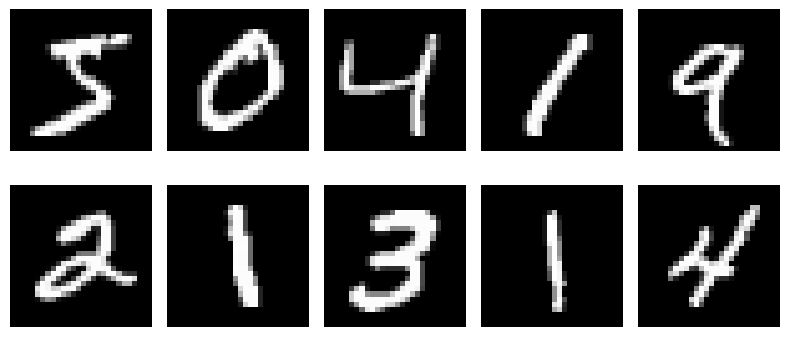

Normalized dataset shape: (60000, 28, 28, 1)
Number of batches: 468


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)
tf.keras.utils.set_random_seed(42)

(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()

print("Dataset shape:", x_train.shape)
print("Image dimensions:", x_train.shape[1:])
print("Pixel value range:", x_train.min(), "to", x_train.max())

plt.figure(figsize=(8, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.axis("off")
plt.tight_layout()
plt.show()

x_train = (x_train.astype("float32") - 127.5) / 127.5
x_train = np.expand_dims(x_train, axis=-1)

BUFFER_SIZE = len(x_train)
BATCH_SIZE = 128
NOISE_DIM = 100
EPOCHS = 50

train_dataset = (
    tf.data.Dataset.from_tensor_slices(x_train)
    .shuffle(BUFFER_SIZE, seed=42)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

print("Normalized dataset shape:", x_train.shape)
print("Number of batches:", len(train_dataset))

## PART B: IMPLEMENTING THE GENERATOR AND DISCRIMINATOR

In [ ]:
def build_generator():
    return tf.keras.Sequential([
        layers.Input(shape=(NOISE_DIM,)),
        layers.Dense(7 * 7 * 256, use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),
        layers.Reshape((7, 7, 256)),
        layers.Conv2DTranspose(128, 5, strides=1, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),
        layers.Conv2DTranspose(64, 5, strides=2, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),
        layers.Conv2DTranspose(1, 5, strides=2, padding="same", activation="tanh")
    ])


def build_discriminator():
    return tf.keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(64, 5, strides=2, padding="same"),
        layers.LeakyReLU(),
        layers.Dropout(0.3),
        layers.Conv2D(128, 5, strides=2, padding="same"),
        layers.LeakyReLU(),
        layers.Dropout(0.3),
        layers.Flatten(),
        layers.Dense(1)
    ])


generator = build_generator()
discriminator = build_discriminator()

print("GENERATOR MODEL")
generator.summary()

print("DISCRIMINATOR MODEL")
discriminator.summary()

GENERATOR MODEL


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,945 (8.89 MB)

 Trainable params: 2,305,473 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

## PART C: GAN TRAINING AND PERFORMANCE MONITORING

The Generator and Discriminator are updated in separate steps. One-sided label smoothing is applied to real samples to reduce discriminator overconfidence. GAN losses may fluctuate, so generated image quality should also be evaluated.

In [ ]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

generator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001, beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001, beta_1=0.5)


def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output) * 0.9, real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss


def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)


@tf.function
def train_step(real_images):
    noise = tf.random.normal([BATCH_SIZE, NOISE_DIM])

    with tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)
        generated_images = tf.stop_gradient(generated_images)
        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(generated_images, training=True)
        disc_loss = discriminator_loss(real_output, fake_output)

    disc_gradients = disc_tape.gradient(disc_loss, discriminator.trainable_variables)
    discriminator_optimizer.apply_gradients(zip(disc_gradients, discriminator.trainable_variables))

    noise = tf.random.normal([BATCH_SIZE, NOISE_DIM])

    with tf.GradientTape() as gen_tape:
        generated_images = generator(noise, training=True)
        fake_output = discriminator(generated_images, training=False)
        gen_loss = generator_loss(fake_output)

    gen_gradients = gen_tape.gradient(gen_loss, generator.trainable_variables)
    generator_optimizer.apply_gradients(zip(gen_gradients, generator.trainable_variables))

    return gen_loss, disc_loss


generator_losses = []
discriminator_losses = []

for epoch in range(EPOCHS):
    gen_epoch_loss = tf.keras.metrics.Mean()
    disc_epoch_loss = tf.keras.metrics.Mean()

    for image_batch in train_dataset:
        gen_loss, disc_loss = train_step(image_batch)
        gen_epoch_loss.update_state(gen_loss)
        disc_epoch_loss.update_state(disc_loss)

    generator_losses.append(float(gen_epoch_loss.result().numpy()))
    discriminator_losses.append(float(disc_epoch_loss.result().numpy()))

    print(
        f"Epoch {epoch + 1}/{EPOCHS} - "
        f"Generator Loss: {generator_losses[-1]:.4f} - "
        f"Discriminator Loss: {discriminator_losses[-1]:.4f}"
    )

print("GAN training completed successfully.")

Epoch 1/50 - Generator Loss: 0.7995 - Discriminator Loss: 1.3344
Epoch 2/50 - Generator Loss: 0.8786 - Discriminator Loss: 1.3449
Epoch 3/50 - Generator Loss: 0.9065 - Discriminator Loss: 1.3183
Epoch 4/50 - Generator Loss: 0.8866 - Discriminator Loss: 1.3294
Epoch 5/50 - Generator Loss: 0.8519 - Discriminator Loss: 1.3523
Epoch 6/50 - Generator Loss: 0.8436 - Discriminator Loss: 1.3573
Epoch 7/50 - Generator Loss: 0.8407 - Discriminator Loss: 1.3566
Epoch 8/50 - Generator Loss: 0.8605 - Discriminator Loss: 1.3560
Epoch 9/50 - Generator Loss: 0.8432 - Discriminator Loss: 1.3528
Epoch 10/50 - Generator Loss: 0.8583 - Discriminator Loss: 1.3543
Epoch 11/50 - Generator Loss: 0.8443 - Discriminator Loss: 1.3497
Epoch 12/50 - Generator Loss: 0.8590 - Discriminator Loss: 1.3517
Epoch 13/50 - Generator Loss: 0.8592 - Discriminator Loss: 1.3488
Epoch 14/50 - Generator Loss: 0.8495 - Discriminator Loss: 1.3474
Epoch 15/50 - Generator Loss: 0.8679 - Discriminator Loss: 1.3489
Epoch 16/50 - Gener

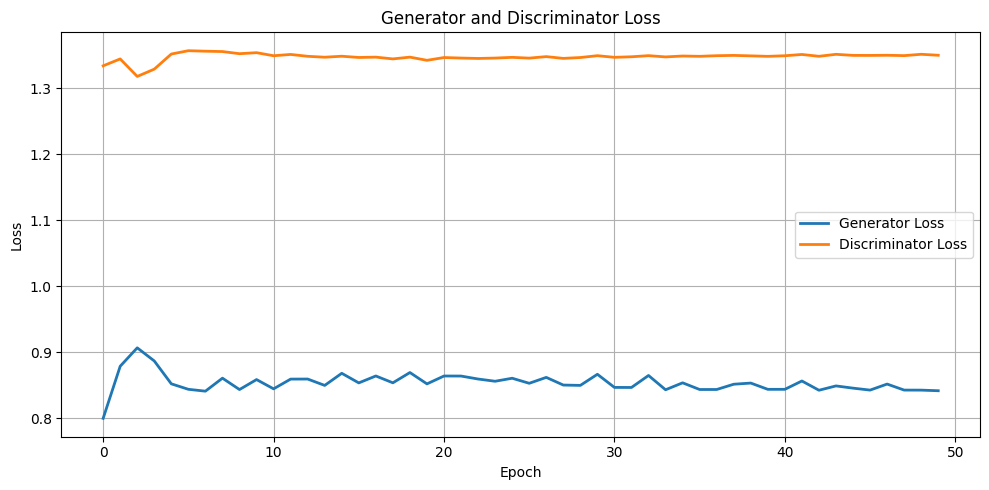

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(generator_losses, label="Generator Loss", linewidth=2)
plt.plot(discriminator_losses, label="Discriminator Loss", linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Generator and Discriminator Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## PART D: LATENT-SPACE FEATURE VISUALIZATION AND EXPERIMENT MANAGEMENT

A standard GAN does not contain a separate Encoder. Its random noise input vectors form the latent-space representations used to generate images.

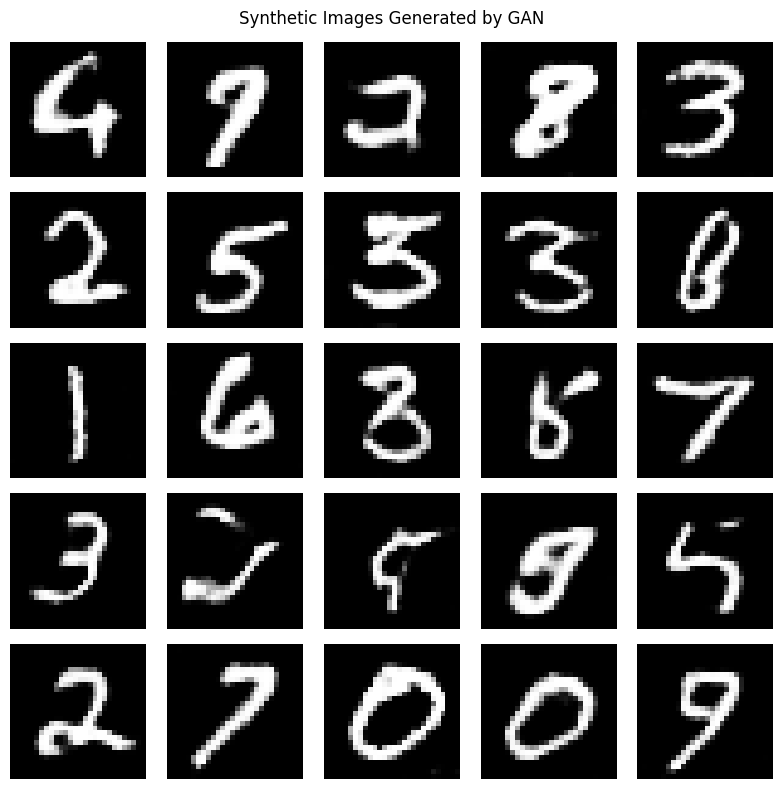

In [ ]:
seed = tf.random.normal([25, NOISE_DIM])
predictions = generator(seed, training=False)

plt.figure(figsize=(8, 8))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(predictions[i, :, :, 0] * 0.5 + 0.5, cmap="gray")
    plt.axis("off")

plt.suptitle("Synthetic Images Generated by GAN")
plt.tight_layout()
plt.show()

Latent-space representation shape: (25, 100)
First latent vector:
[ 3.2746851e-01 -8.4262580e-01  3.1943369e-01 -1.4075519e+00
 -2.3880599e+00 -1.0392479e+00 -5.5732322e-01  5.3970701e-01
  1.6994323e+00  2.8893656e-01 -1.5066116e+00 -2.6454741e-01
 -5.9722406e-01 -1.9171132e+00 -6.2044144e-01  8.5040230e-01
 -4.0604794e-01 -3.0258412e+00  9.0584642e-01  2.9855987e-01
 -2.2561555e-01 -7.6164430e-01 -1.8917141e+00 -9.3847126e-01
  7.7852213e-01 -4.7338894e-01  9.7772694e-01  2.4694404e-01
  2.0573746e-01 -5.2562326e-01  3.2410017e-01  2.5454091e-02
 -1.0638496e-01 -6.3694745e-01  1.1603122e+00  2.5073591e-01
 -4.1728503e-01  4.0125781e-01 -1.4145443e+00 -5.9318572e-01
 -1.6617213e+00  3.3567193e-01  1.0815628e-01  2.3479679e-01
 -5.6668764e-01 -3.5819843e-01  8.8698614e-01  5.2744764e-01
  7.0402247e-01 -3.3421248e-01  2.1639644e-01 -9.7485447e-01
 -2.0757681e-01 -3.6477294e-02 -1.3353444e+00  6.8858552e-01
  1.1110831e+00  4.0130249e-01  6.3205862e-01 -3.9030614e-01
  1.4612000e+00 -6.

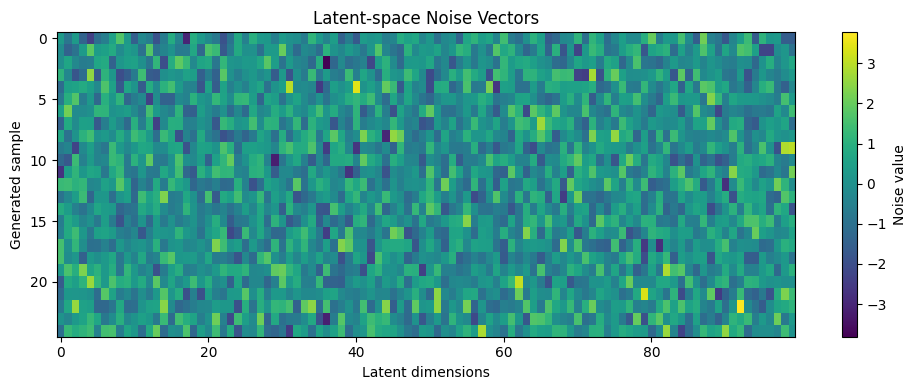

In [ ]:
noise_vectors = seed.numpy()

print("Latent-space representation shape:", noise_vectors.shape)
print("First latent vector:")
print(noise_vectors[0])

plt.figure(figsize=(10, 4))
plt.imshow(noise_vectors, aspect="auto", cmap="viridis")
plt.colorbar(label="Noise value")
plt.xlabel("Latent dimensions")
plt.ylabel("Generated sample")
plt.title("Latent-space Noise Vectors")
plt.tight_layout()
plt.show()

### Latent Space Interpolation

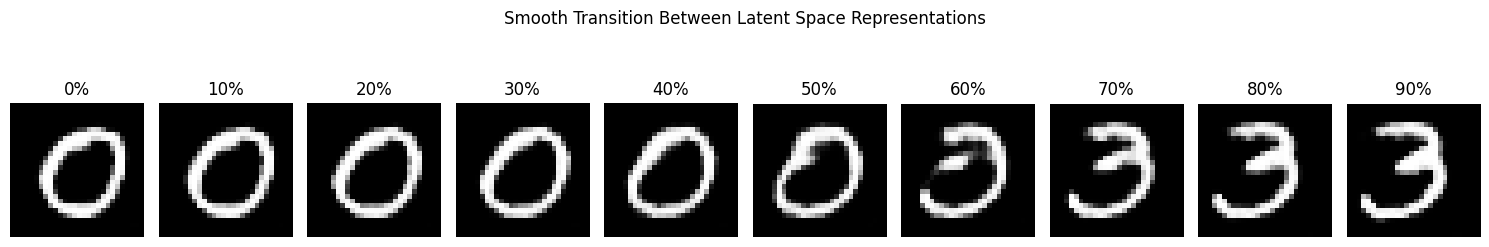

In [ ]:
import numpy as np

def interpolate_points(p1, p2, n_steps=10):
    ratios = np.linspace(0, 1, num=n_steps)
    vectors = list()
    for ratio in ratios:
        v = (1.0 - ratio) * p1 + ratio * p2
        vectors.append(v)
    return np.asarray(vectors)

start_vector = tf.random.normal([1, NOISE_DIM])
end_vector = tf.random.normal([1, NOISE_DIM])

interpolated_vectors = interpolate_points(start_vector[0], end_vector[0], n_steps=10)
interpolated_vectors = tf.convert_to_tensor(interpolated_vectors, dtype=tf.float32)

generated_transition = generator(interpolated_vectors, training=False)

plt.figure(figsize=(15, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(generated_transition[i, :, :, 0] * 0.5 + 0.5, cmap="gray")
    plt.axis("off")
    plt.title(f"{i*10}%")
plt.suptitle("Smooth Transition Between Latent Space Representations")
plt.tight_layout()
plt.show()

### Reconstruction of Original Images via GAN Inversion

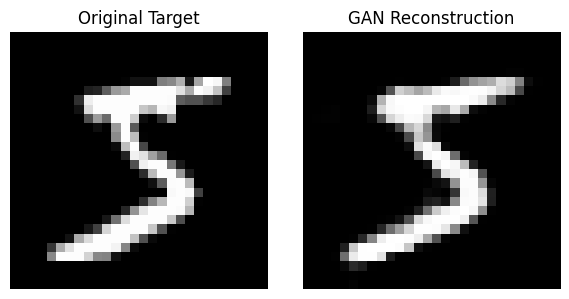

In [ ]:
target_image = tf.convert_to_tensor(x_train[0:1], dtype=tf.float32)

reconstructed_latent = tf.Variable(tf.random.normal([1, NOISE_DIM]))
optimizer = tf.keras.optimizers.Adam(learning_rate=0.05)

steps = 200
for step in range(steps):
    with tf.GradientTape() as tape:
        gen_image = generator(reconstructed_latent, training=False)
        loss = tf.reduce_mean(tf.square(target_image - gen_image))

    grads = tape.gradient(loss, [reconstructed_latent])
    optimizer.apply_gradients(zip(grads, [reconstructed_latent]))

reconstructed_image = generator(reconstructed_latent, training=False)

plt.figure(figsize=(6, 3))
plt.subplot(1, 2, 1)
plt.imshow(target_image[0, :, :, 0] * 0.5 + 0.5, cmap="gray")
plt.title("Original Target")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(reconstructed_image[0, :, :, 0] * 0.5 + 0.5, cmap="gray")
plt.title("GAN Reconstruction")
plt.axis("off")

plt.tight_layout()
plt.show()

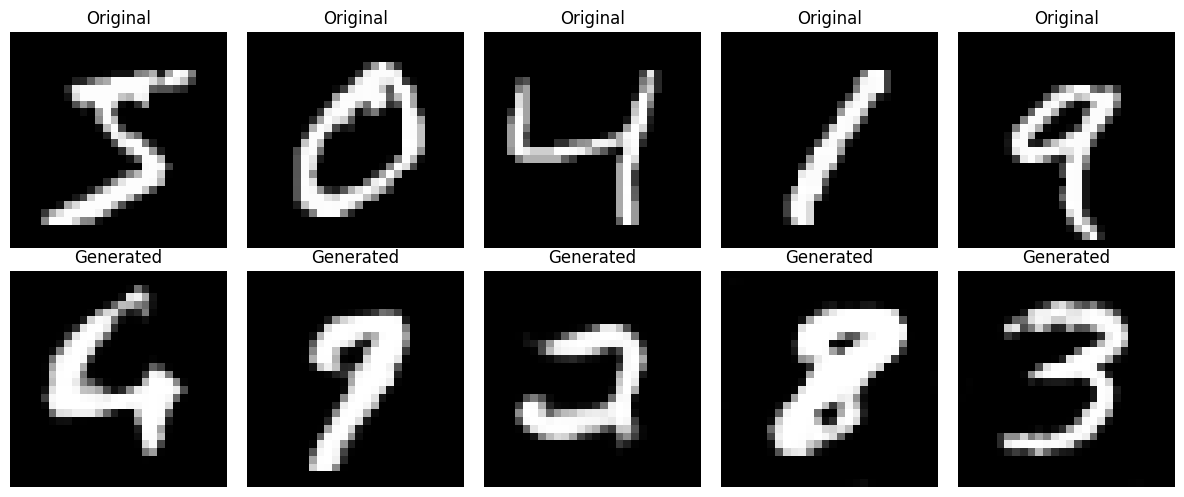

In [ ]:
plt.figure(figsize=(12, 5))

for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i, :, :, 0] * 0.5 + 0.5, cmap="gray")
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, 5, i + 6)
    plt.imshow(predictions[i, :, :, 0] * 0.5 + 0.5, cmap="gray")
    plt.title("Generated")
    plt.axis("off")

plt.tight_layout()
plt.show()

## SAVE THE TRAINED MODELS

In [ ]:
generator.save("gan_generator.keras")
discriminator.save("gan_discriminator.keras")
print("Generator and Discriminator models saved successfully.")

Generator and Discriminator models saved successfully.
